<a href="https://colab.research.google.com/github/naubergois/curso-segmentacao-colab/blob/main/notebooks/06-ressonancia.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 6. Ressonância

A ressonância também é uma pilha de cortes, mas o número não é densidade. É sinal. No mesmo cérebro, gordura, água e osso trocam de claro e escuro conforme o peso do exame. Aqui o crânio fica escuro e o cérebro, cinza.

A máscara é o maior bloco acima de um corte de intensidade. No corte de lado, esse bloco é o cérebro, e o rosto fica de fora. Não é substância branca contra cinzenta. É o tecido contra o fundo.

O volume é o MRHead, doado ao 3D Slicer para uso sem restrição. Tem uns 7 MB.

> No Colab: **Ambiente de execução → Executar tudo**. CPU chega.

In [1]:
!pip install -q pynrrd

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mascaras_originais(resultado):
    """Máscaras no tamanho da foto, como array booleano (n, altura, largura).

    A rede responde numa grade menor que a imagem. Aqui a máscara é esticada
    de volta ao tamanho original, para a área bater com os pixels da foto.
    """
    import cv2
    import numpy as np

    altura, largura = resultado.orig_shape
    if resultado.masks is None or len(resultado.masks) == 0:
        return np.zeros((0, altura, largura), dtype=bool)
    saida = []
    for mascara in resultado.masks.data.cpu().numpy():
        mascara = cv2.resize(mascara, (largura, altura), interpolation=cv2.INTER_NEAREST)
        saida.append(mascara > 0.5)
    return np.stack(saida)


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

In [3]:
import nrrd
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt

arquivo = baixar("https://github.com/Slicer/SlicerTestingData/releases/download/SHA256/cc211f0dfd9a05ca3841ce1141b292898b2dd2d3f08286affadf823a7e58df93", "rm-cabeca.nrrd")
volume, _cabecalho = nrrd.read(arquivo)
volume = volume.astype(np.float32)
print(f"{volume.shape[0]} x {volume.shape[1]} x {volume.shape[2]}")
print(f"sinal de {volume.min():.0f} a {volume.max():.0f}")
assert volume.ndim == 3

rm-cabeca.nrrd: 6.6 MB
256 x 256 x 130
sinal de 0 a 279


## Dois jeitos de cortar a mesma cabeça

Um corte atravessa os olhos. O outro mostra a cabeça de lado, com o cerebelo embaixo. Os dois saem do mesmo volume. Muda o eixo.

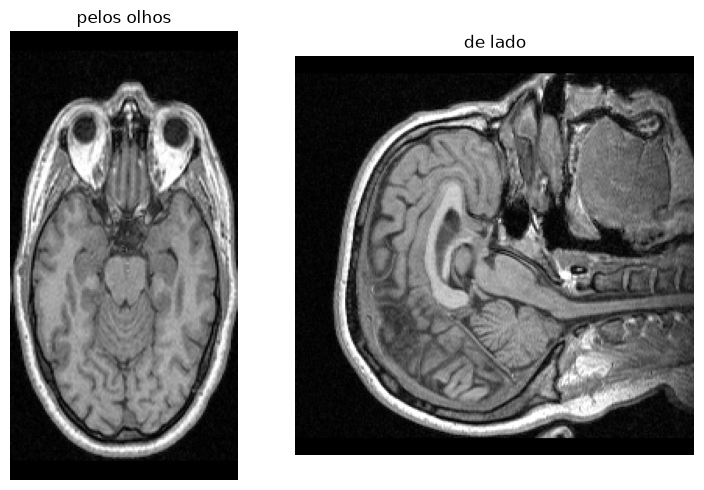

In [4]:
def cinza(img):
    baixo, alto = np.percentile(img, [1, 99])
    return np.clip((img - baixo) / (alto - baixo + 1e-6), 0, 1)

axial = volume[:, volume.shape[1] // 2, :]
sagital = volume[:, :, volume.shape[2] // 2]

fig, eixos = plt.subplots(1, 2, figsize=(8, 5))
eixos[0].imshow(cinza(axial), cmap="gray")
eixos[0].set_title("pelos olhos")
eixos[1].imshow(cinza(sagital), cmap="gray")
eixos[1].set_title("de lado")
for eixo in eixos:
    eixo.axis("off")
plt.tight_layout()
plt.show()

## A máscara no corte de lado

O fundo é quase zero. O que passa de um patamar vira candidato. A abertura come a borda fininha. O maior pedaço que sobra é o cérebro. Olho e pele, quando se separam, ficam de fora.

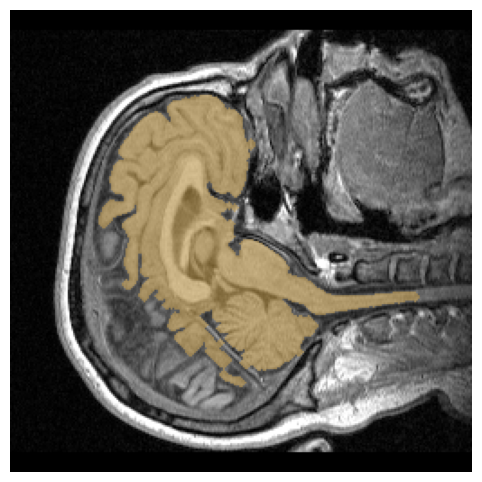

o maior bloco cobre 16.3% do corte de lado


In [5]:
def mascara_tecido(fatia):
    vivos = fatia[fatia > 5]
    patamar = np.percentile(vivos, 40) if len(vivos) else 0
    mascara = fatia > patamar
    mascara = ndimage.binary_opening(mascara, iterations=2)
    mascara = ndimage.binary_fill_holes(mascara)
    rotulo, n = ndimage.label(mascara)
    if n == 0:
        return mascara
    tamanhos = ndimage.sum(np.ones_like(rotulo), rotulo, range(1, n + 1))
    return rotulo == (1 + int(np.argmax(tamanhos)))

cerebro = mascara_tecido(sagital)
cor = plt.cm.gray(cinza(sagital))[..., :3]
cor[cerebro] = 0.55 * cor[cerebro] + 0.45 * np.array([0.85, 0.65, 0.25])
plt.figure(figsize=(6, 6))
plt.imshow(cor)
plt.axis("off")
plt.show()
print(f"o maior bloco cobre {cerebro.mean() * 100:.1f}% do corte de lado")

## O corte dos olhos

A mesma conta, agora no corte que atravessa os olhos. O patamar sobe um pouco, para o cinza do cérebro não grudar na pele. O que a máscara pega aqui é o miolo da cabeça, não o crânio.

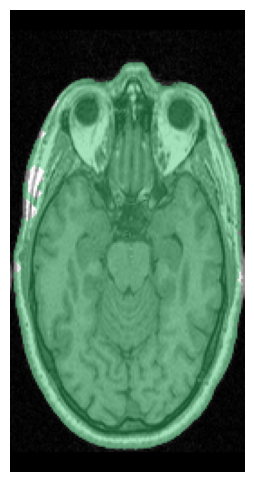

miolo: 64.8% do corte


In [6]:
def mascara_miolo(fatia):
    mascara = (fatia > 35) & (fatia < 120)
    mascara = ndimage.binary_opening(mascara, iterations=1)
    mascara = ndimage.binary_closing(mascara, iterations=2)
    mascara = ndimage.binary_fill_holes(mascara)
    rotulo, n = ndimage.label(mascara)
    borda = set(rotulo[0, :]) | set(rotulo[-1, :]) | set(rotulo[:, 0]) | set(rotulo[:, -1])
    borda.discard(0)
    for pedaco in borda:
        mascara[rotulo == pedaco] = False
    rotulo, n = ndimage.label(mascara)
    if n == 0:
        return mascara
    tamanhos = ndimage.sum(np.ones_like(rotulo), rotulo, range(1, n + 1))
    return rotulo == (1 + int(np.argmax(tamanhos)))

miolo = mascara_miolo(axial)
cor = plt.cm.gray(cinza(axial))[..., :3]
cor[miolo] = 0.55 * cor[miolo] + 0.45 * np.array([0.2, 0.75, 0.4])
plt.figure(figsize=(6, 6))
plt.imshow(cor)
plt.axis("off")
plt.show()
print(f"miolo: {miolo.mean() * 100:.1f}% do corte")

## O que fica

Tomografia separa pelo peso do pixel. Ressonância separa pelo sinal, e o número muda se o exame for outro peso. As duas máscaras são conta de limiar. Nenhuma das duas lê um laudo, e nenhuma separa lesão de tecido sadio.

Para uma lesão virar classe, alguém marca o contorno em muitos exames. Aí o treino da aula 4 passa a ter o que aprender.